In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.004372275875637335 + 2.4106504279084754e-5im -0.0001939657269582766 - 4.204575293207368e-6im … 0.00156972489085637 - 0.0034195938410036585im -0.0007111555378946302 - 0.004256733164382547im; -0.003047741411537763 + 0.002716492813713066im -4.4227706797508035e-5 - 0.001443083870264053im … -4.128657590980587e-6 - 0.0026507746302675563im -0.0008458940042454882 + 0.0012621987032145905im; 0.0008405250331566096 + 0.0010868213001834508im 0.00040155299354685244 + 0.0005700465228292849im … -0.0037826961162132754 - 0.0013294627529850788im -0.0014385002044416837 - 0.0005749757276690717im;;; 0.0010894209858901497 + 0.000266055948910205im 0.0010357314675980545 - 0.0003393075216815683im … 0.0023088808445374605 - 0.0030985962531074915im 0.00017862220484332616 + 0.0023832086519795692im; 0.001060748458651132 + 0.0011448344205523566im 0.0031148444767584963 - 0.0006843826714055676im … -0.00046773815410657455 - 0.00108663756885803

In [3]:
P=Onestep()
i=0.1
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)*i
W2=Generate_weight(hop)*i
W3=Generate_weight(hop)*i
W4=Generate_weight(hop)*i
W5=Generate_weight(hop)*i
W6=Generate_weight(hop)*i


9-element Vector{Spin_matrix}:
 [-0.019920189493361898 + 0.0im 0.08819075377558444 + 0.0im -0.0020425040549134645 + 0.0im -0.11195104017693747 + 0.0im; -0.09069944282285285 + 0.0im 0.222259781554852 + 0.0im -0.023471860179056708 + 0.0im -0.05983573405770615 + 0.0im; -0.0968744172538266 + 0.0im -0.009226319124311965 + 0.0im 0.11011742743947993 + 0.0im -0.08587814395188509 + 0.0im; 0.08678984273400181 + 0.0im -0.04376756135658797 + 0.0im 0.025601328347656317 + 0.0im 0.020587651334284515 + 0.0im]
 [0.06120615723730073 + 0.0im -0.21046428367272846 + 0.0im 0.005169341926758467 + 0.0im 0.14728367631290265 + 0.0im; 0.09562572247354055 + 0.0im 0.06116861389576185 + 0.0im 0.0570543230595995 + 0.0im -0.16023583354786658 + 0.0im; -0.1582171720689683 + 0.0im -0.036825858540164604 + 0.0im -0.06758433748109048 + 0.0im 0.06335337684207636 + 0.0im; -0.1243878737849452 + 0.0im 0.09149432159808414 + 0.0im 0.0031998013404942226 + 0.0im -0.07709985183883421 + 0.0im]
 [-0.0860984974908037 + 0.0im -0.106875

In [4]:
# W1 = load("PTC_weight.jld2", "W")  # OK
# W2 = load("PTC_weight.jld2", "W")  # OK
# W3 = load("PTC_weight.jld2", "W")  # OK
# W4 = load("PTC_weight.jld2", "W")  # OK
# W5 = load("PTC_weight.jld2", "W")  # OK
# W6 = load("PTC_weight.jld2", "W")  # OK

In [5]:
layer1=CPTC_Layer(hop,W1)
Norm=NormLayer()
cNorm=complexNormLayer()
layer2=PTC_Layer(hop,W2 ,true)
act=Softmax()
layer1=Attention_Layer(layer1,sqrt(length(x)) , act,true)
layer3=Attention_Layer(CPTC_Layer(hop,W3),sqrt(length(x)),act,true)
layer4=PTC_Layer(hop,W4,true)
layer5=Attention_Layer(CPTC_Layer(hop,W5),sqrt(length(x)),act,true)
layer6=PTC_Layer(hop,W6)
layers=[layer1,Norm,layer2,cNorm,layer3,Norm,layer4,cNorm,layer5,Norm,layer6]
# layers=[layer1,Norm,layer2]

11-element Vector{LMP.Layer_types.Layer}:
 Attention_Layer(CPTC_Layer(Spin_matrix[[0.13534949890051715 + 0.0im 0.11766243442122773 + 0.0im 0.07580390165718637 + 0.0im 0.047009247065965404 + 0.0im; 0.0259238889650333 + 0.0im 0.014423372067936244 + 0.0im 0.24919836056566297 + 0.0im 0.011318914629271589 + 0.0im; -0.025346006257835382 + 0.0im 0.026322472914702057 + 0.0im 0.038006513791096264 + 0.0im 0.0889243819827169 + 0.0im; 0.1667907910579754 + 0.0im 0.037991296264384966 + 0.0im 0.17400537104606628 + 0.0im -6.471072500315693e-6 + 0.0im], [-0.1407663386872887 + 0.0im 0.021612632844119056 + 0.0im -0.05037409537079932 + 0.0im -0.07835699432592373 + 0.0im; 0.0079195622711118 + 0.0im -0.07812119678749539 + 0.0im 0.13715923871982116 + 0.0im 0.1562285424297801 + 0.0im; 0.023583226248029263 + 0.0im 0.06201463204623114 + 0.0im -0.08896880259150185 + 0.0im -0.029512417763543786 + 0.0im; -0.01567262061297214 + 0.0im 0.018342306494863708 + 0.0im -0.11781353592335507 + 0.0im 0.0011155922883049458 + 

In [6]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-9.157878058574587e-6 - 1.2337941664133102e-5im -9.859698289004053e-6 + 7.566449639362651e-6im … 6.164982261595317e-6 - 7.944327844253031e-7im -4.143465609159756e-6 + 5.002785968894057e-6im; -7.3761596603048255e-6 + 5.638386850018463e-6im -4.3470867136077e-6 - 1.1564073620314201e-6im … 3.50564388929021e-6 + 1.6177736364380796e-6im 5.257517909868161e-6 - 7.427153750533275e-6im; -2.903148760043692e-6 + 6.1058415827202324e-6im -5.223689115794302e-7 + 3.815778487122366e-7im … -5.988096414714425e-7 + 4.33819939925631e-6im -1.086889625484234e-6 - 6.207986982981506e-6im;;; -3.0999068489967565e-7 - 2.0469203626850644e-6im 9.589129260310525e-6 - 6.8115151974265996e-6im … 5.108551538758433e-6 + 3.873072054945253e-6im -8.26711614840239e-6 - 2.7142232816959352e-6im; -1.6042521653235217e-6 - 1.278464112129096e-6im -5.407357596126692e-6 - 1.1621163667615386e-5im … -5.122888165576117e-6 - 3.619203000488803e-6im 8.872894964196

In [7]:
opt=Adam()
opt.α=0.01

0.01

In [8]:
println(norm2(layers(x)))

0.26098352799887936 + 0.0im


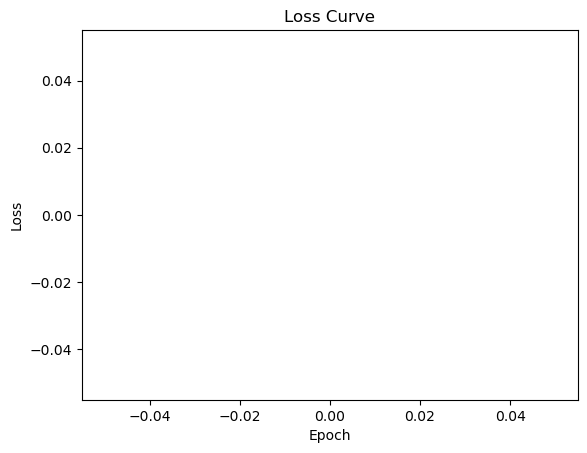

Epoch: 1, Loss: 1.0204093085118762 + 0.0im
Epoch: 2, Loss: 0.9708638007053823 + 0.0im
Epoch: 3, Loss: 0.9187965372337787 + 0.0im
Epoch: 4, Loss: 0.8765624533938328 + 0.0im
Epoch: 5, Loss: 0.8450914483029294 + 0.0im
Epoch: 6, Loss: 0.8261132968745867 + 0.0im
Epoch: 7, Loss: 0.8044631499042527 + 0.0im
Epoch: 8, Loss: 0.7926630391349127 + 0.0im
Epoch: 9, Loss: 0.7830830267964399 + 0.0im
Epoch: 10, Loss: 0.7677482600893507 + 0.0im
Epoch: 11, Loss: 0.7656293469615139 + 0.0im
Epoch: 12, Loss: 0.7685606478444219 + 0.0im
Epoch: 13, Loss: 0.7784007850113415 + 0.0im
Epoch: 14, Loss: 0.7823645659435724 + 0.0im
Epoch: 15, Loss: 0.7902920463696325 + 0.0im
Epoch: 16, Loss: 0.7805599218531222 + 0.0im
Epoch: 17, Loss: 0.7647093832784918 + 0.0im
Epoch: 18, Loss: 0.7531657019225054 + 0.0im
Epoch: 19, Loss: 0.752786358269556 + 0.0im
Epoch: 20, Loss: 0.7541183206340635 + 0.0im
Epoch: 21, Loss: 0.7398974321183879 + 0.0im
Epoch: 22, Loss: 0.7236627387694297 + 0.0im
Epoch: 23, Loss: 0.7091383208078038 + 0.0i

In [ ]:
train(opt,layers,x,t,D,epochs=10000)